In [ ]:
## For some arithmetic and Matrix Operations
import numpy as np

## Dataframe Manipulation
import pandas as pd

## For Visualization
import matplotlib.pyplot as plt

## For Visualization too
import seaborn as sns

## Creating Pipeline
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline


## Creating a function transformer
from sklearn.preprocessing import FunctionTransformer

## For Column Transformer
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector


## For preprocessing
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder

## For missing values
from sklearn.impute import SimpleImputer

## Getting the recall score on our train set
from sklearn.metrics import recall_score

## Getting the accuracy score on train set
from sklearn.metrics import accuracy_score

## Getting the classification report from our train set
from sklearn.metrics import classification_report

## Cross validation
from sklearn.model_selection import cross_val_score

## Gridsearch CV
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

## Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Features.csv to Features.csv
Saving Outcome.csv to Outcome.csv


In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import f1_score, classification_report
import numpy as np
import pandas as pd

X = pd.read_csv('Features.csv')
y = pd.read_csv('Outcome.csv')


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=22, stratify=y)

# Step 2: 定义10折StratifiedKFold
kf = StratifiedKFold(n_splits=10, shuffle=True)

# Step 3: 在训练集上使用10折交叉验证
f1_scores = []  # 用于保存每折的F1分数
for train_index, val_index in kf.split(X_train, y_train):
    # Use .iloc to select rows by index:
    X_train_fold, X_val_fold = X_train.iloc[train_index], X_train.iloc[val_index]
    y_train_fold, y_val_fold = y_train.iloc[train_index], y_train.iloc[val_index]


    # 训练模型
    model = LinearDiscriminantAnalysis()
    model.fit(X_train_fold, y_train_fold)

    # 在验证集上预测并计算F1 score
    y_val_pred = model.predict(X_val_fold)
    f1 = f1_score(y_val_fold, y_val_pred, average='weighted')
    f1_scores.append(f1)

# 输出交叉验证的平均F1分数
print(f"Average F1 score from 10-fold CV: {np.mean(f1_scores):.4f}")

# Step 4: 在完整训练集上训练模型并在测试集上评估
final_model = LinearDiscriminantAnalysis()
final_model.fit(X_train, y_train)
y_test_pred = final_model.predict(X_test)

print("Features shape:", X.shape)
print("Outcome shape:", y.shape)
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Classification Report on Test Set:")
print(classification_report(y_test, y_test_pred))

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for exam

Average F1 score from 10-fold CV: 0.7425


/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Features shape: (531916, 16)
Outcome shape: (531916, 1)
Training set shape: (372341, 16)
Test set shape: (159575, 16)
Classification Report on Test Set:
              precision    recall  f1-score   support

           0       0.75      0.74      0.74     79787
           1       0.74      0.75      0.75     79788

    accuracy                           0.74    159575
   macro avg       0.74      0.74      0.74    159575
weighted avg       0.74      0.74      0.74    159575



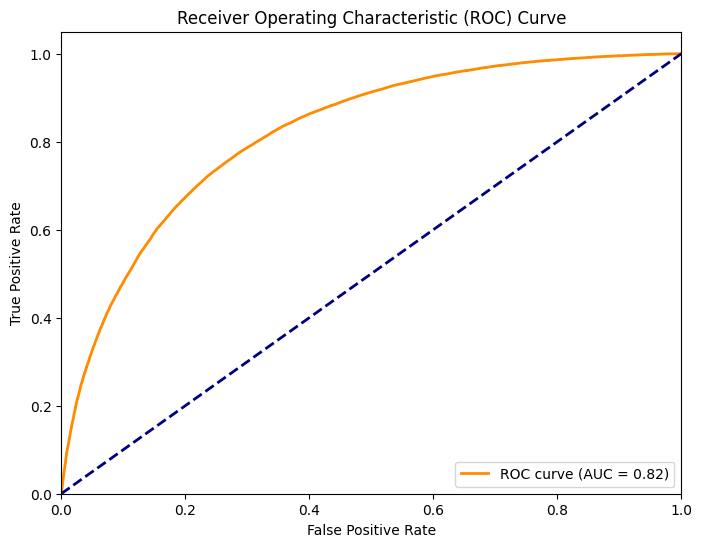

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

# ... (Your existing code) ...

# Predict probabilities for the test set
y_test_proba = final_model.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

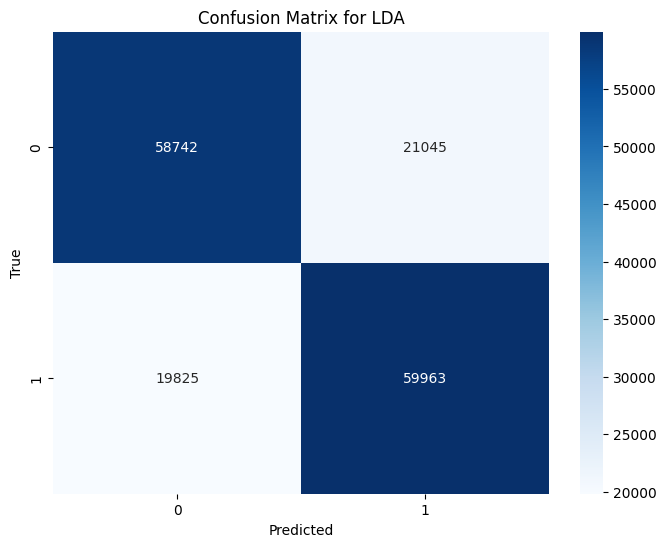

In [ ]:
# plot the confusion matrix for LDA

from sklearn.metrics import confusion_matrix
import seaborn as sns


# Compute the confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Plot the confusion matrix using seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.unique(y_test_pred), yticklabels=np.unique(y_test))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix for LDA')
plt.show()

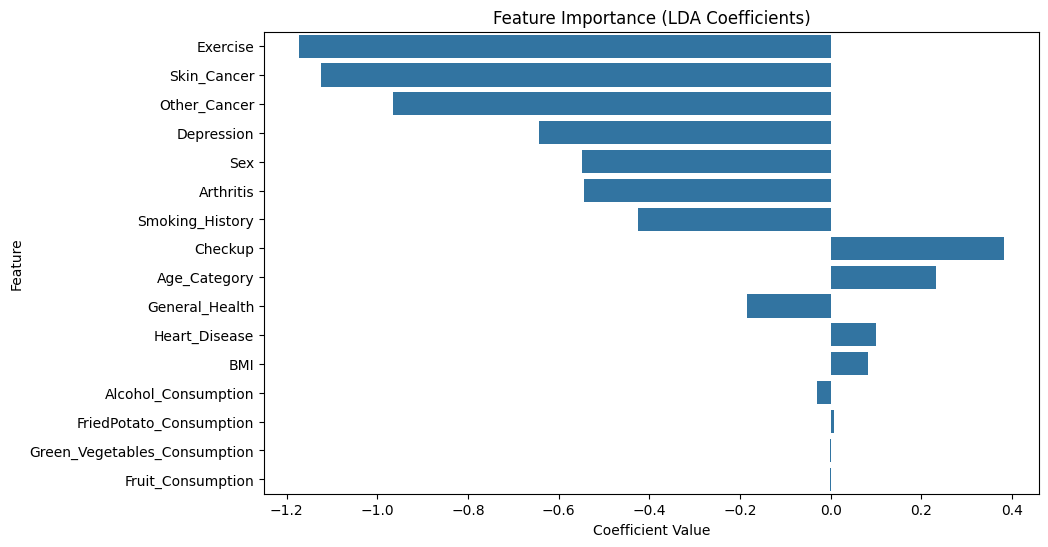

In [ ]:
# understand the importance of features of the LDA model based on the coefficients of the model’s equation Standardization was applied to put all variables in the same scale, and plot the feature importance

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# ... (Your existing code) ...

# Assuming 'final_model' is your trained LDA model
# Access the coefficients
coefficients = final_model.coef_[0]

# Create a DataFrame for better visualization
feature_importance = pd.DataFrame({'Feature': X.columns, 'Coefficient': coefficients})

# Sort the DataFrame by absolute coefficient value for better visualization
feature_importance = feature_importance.reindex(feature_importance['Coefficient'].abs().sort_values(ascending=False).index)


# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=feature_importance)
plt.title('Feature Importance (LDA Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.show()

# ... (Rest of your existing code) ...